# Tutorial 6: grain boundaries and three-layer interfaces (EMT)

Both features work with every engine; EMT keeps this tutorial to a few seconds.

* **Symmetric tilt boundaries**: the upper grain is the mirror image of the lower one through the boundary plane (hkl),
  e.g. (310) of a cubic crystal gives the Σ5 (310)[001] boundary. Mirror planes of the crystal give the perfect crystal
  (γ = 0), and fcc (111) the Σ3 coherent twin.
* **Twist boundaries**: the upper grain is rotated about the normal by the coincidence-site-lattice (CSL) angle given
  by two integers (m, n), for square (cubic (100)) and hexagonal (fcc (111)) planes.
* **Three-layer interfaces** slab1 | slab2 | slab3, e.g. a coating or an interlayer.

The same calculations from the command line:

```bash
interfacer -i1 Cu.cif -m1 3 1 0 --gb tilt  -prog ase -ase_pot EMT
interfacer -i1 Cu.cif -m1 1 0 0 --gb twist --gb_mn 2 1 -prog ase -ase_pot EMT
interfacer -i1 Cu.cif -i2 Ni.cif -i3 Cu.cif -m1 1 0 0 -m2 1 0 0 -m3 1 0 0 -cr1 2 -cr2 2 -cr3 2 -prog ase -ase_pot EMT
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from ase.io import read
from ase.visualize.plot import plot_atoms

from interfacer.calculators import CalcSettings, get_engine
from interfacer.grainboundary import symmetric_tilt_gb, twist_gb
from interfacer.log import setup_logging
from interfacer.workflow import InterfaceWorkflow, WorkflowConfig

setup_logging(-1)   # warnings only
import warnings
warnings.filterwarnings("ignore", message="Occupancies")   # harmless note of ASE's CIF reader
cu = read("Cu.cif")
engine = get_engine("ase", CalcSettings(ase_pot="EMT", steps=300, fmax=0.02, relax_cell_bulk=True, outdir="OUTPUT"))
J = 0.160217663     # eV/nm^2 -> J/m^2

## 1. Symmetric tilt boundaries about [001]

The tilt angle between the two grains is $\theta = 2\arctan(k/h)$ for the boundary plane (h k 0).

(100)  theta =   0.0 deg   20 atoms  gamma_GB = 0.000 J/m^2


(510)  theta =  22.6 deg  108 atoms  gamma_GB = 1.061 J/m^2


(310)  theta =  36.9 deg   64 atoms  gamma_GB = 0.962 J/m^2


(210)  theta =  53.1 deg   40 atoms  gamma_GB = 1.054 J/m^2


(320)  theta =  67.4 deg   64 atoms  gamma_GB = 0.894 J/m^2
(110)  theta =  90.0 deg   20 atoms  gamma_GB = -0.000 J/m^2


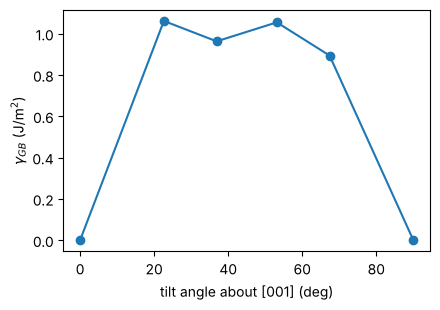

In [2]:
results = []
for hkl in [(1, 0, 0), (5, 1, 0), (3, 1, 0), (2, 1, 0), (3, 2, 0), (1, 1, 0)]:
    cfg = WorkflowConfig(gb="tilt", miller1=hkl, creps1=3, outdir="OUTPUT", outfile="gb.out")
    r = InterfaceWorkflow(engine, cfg).run(cu.copy()).grain_boundaries[0]
    theta = 2 * np.degrees(np.arctan2(hkl[1], hkl[0]))
    results.append((theta, r.gamma_gb_J))
    print("(%d%d%d)  theta = %5.1f deg  %3d atoms  gamma_GB = %.3f J/m^2" % (*hkl, theta, r.natoms, r.gamma_gb_J))
t, g = np.array(results).T
plt.figure(figsize=(4.5, 3.2))
plt.plot(t, g, "o-")
plt.xlabel("tilt angle about [001] (deg)")
plt.ylabel(r"$\gamma_{GB}$ (J/m$^2$)")
plt.tight_layout()

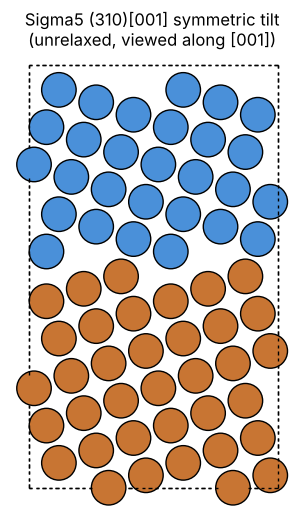

In [3]:
gb, g1, _ = symmetric_tilt_gb(cu, (3, 1, 0), creps=3)
# view along the tilt axis [001] (the short in-plane cell vector); grain 1 (first atoms) and grain 2 in two colours
v = min(gb.cell[:2], key=np.linalg.norm)
view = gb.copy()
view.rotate(90 - np.degrees(np.arctan2(v[1], v[0])), "z", rotate_cell=True)
colors = ["#c87533"] * len(g1) + ["#4a90d9"] * (len(gb) - len(g1))
fig, ax = plt.subplots(figsize=(4, 6))
plot_atoms(view, ax, rotation="-90x", radii=0.6, colors=colors)
ax.set_title("Sigma5 (310)[001] symmetric tilt\n(unrelaxed, viewed along [001])"); ax.set_axis_off()

## 2. Twist boundaries

Σ and the twist angle follow from (m, n); the angle is reported as the smallest equivalent rotation.

In [4]:
for hkl, mn in [((1, 0, 0), (2, 1)), ((1, 0, 0), (3, 2)), ((1, 1, 1), (2, 1)), ((1, 1, 1), (3, 1))]:
    _, _, _, angle, sigma = twist_gb(cu, hkl, *mn)
    cfg = WorkflowConfig(gb="twist", miller1=hkl, gb_mn=mn, creps1=2, outdir="OUTPUT", outfile="gb.out")
    r = InterfaceWorkflow(engine, cfg).run(cu.copy()).grain_boundaries[0]
    print("(%d%d%d) m,n = %d,%d  Sigma%-3d %5.2f deg  %3d atoms  gamma_GB = %.3f J/m^2"
          % (*hkl, *mn, r.sigma, r.twist_angle, r.natoms, r.gamma_gb_J))

(100) m,n = 2,1  Sigma5   36.87 deg   80 atoms  gamma_GB = 0.789 J/m^2


(100) m,n = 3,2  Sigma13  22.62 deg  208 atoms  gamma_GB = 0.696 J/m^2


(111) m,n = 2,1  Sigma7   21.79 deg  112 atoms  gamma_GB = 0.339 J/m^2


(111) m,n = 3,1  Sigma13  27.80 deg  208 atoms  gamma_GB = 0.352 J/m^2


## 3. A three-layer interface Cu | Ni | Cu

The three slabs get a common in-plane cell; the stack has two interfaces, so its total work of adhesion is about twice
that of the single Cu | Ni interface.

Cu|Ni     W_ad       = 1.25 J/m^2
Cu|Ni|Cu  W_ad_total = 2.39 J/m^2 (two interfaces)


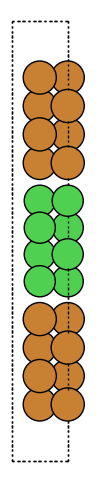

In [5]:
cfg = WorkflowConfig(miller1=(1, 0, 0), miller2=(1, 0, 0), miller3=(1, 0, 0), creps1=2, creps2=2, creps3=2, sep2=2.0,
                     max_slab_dimension=20, outdir="OUTPUT", outfile="trilayer.out")
res = InterfaceWorkflow(engine, cfg).run(cu.copy(), read("Ni.cif"), cu.copy())
single, tri = res.interfaces[0], res.trilayers[0]
print("Cu|Ni     W_ad       = %.2f J/m^2" % single.W_ad_J)
print("Cu|Ni|Cu  W_ad_total = %.2f J/m^2 (two interfaces)" % tri.W_ad_total_J)
fig, ax = plt.subplots(figsize=(4, 6))
plot_atoms(read("OUTPUT/%s_opted.xyz" % tri.name), ax, rotation="-90x", radii=0.8)
ax.set_axis_off()